# TP2 - Visión por Computadora I

Especialización en Inteligencia Artificial (CEIA), FIUBA.

**Integrantes**

- Hernando Alexis Gonzalez
- Victoria Villalba Teves
- Silvert Kevin Quispe Pacompia

**Consigna**
Implementar un detector de máximo enfoque sobre un video aplicando técnicas cámaras digitales modernas. El video a procesar será: “focus_video.mov”.
1. Se debe implementar un algoritmo que dada una imagen, o región, calcule la métrica propuesta en el paper "Image SharpnessMeasure for Blurred Images in Frequency Domain“ y realizar dos experimentos:

    1. Medición sobre todo el frame
    2. Medición sobre una ROI ubicada en el centro del frame. Area de la ROI = 5 o 10% del area total del frame.
    
Para cada experimento se debe presentar :- Una curva o varias curvas que muestren la evolución de la métrica frame a frame donde se vea claramente cuando el algoritmo detecto la  región de máximo enfoque.

El algoritmo de detección a implementar debe detectar y devolver los puntos de máximo enfoque de manera 
automática.

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np


In [3]:
# Video provisto por la catedra en Material_TPs/TP2.
DATA_DIR = Path("Data")
VIDEO_PATH = DATA_DIR / "focus_video.mov"

if not VIDEO_PATH.is_file():
    raise FileNotFoundError(f"No se encontro el video: {VIDEO_PATH.resolve()}")

## Métrica de enfoque en el dominio de la frecuencia

Siguiendo el algoritmo del artículo *Image Sharpness Measure for Blurred Images in Frequency Domain* (De y Masilamani, 2013, secciones 3.1–3.2), calculamos la FFT 2D centrada y su magnitud. Se cuentan los coeficientes cuya magnitud supera `max(magnitud) / 1000`; la métrica `FM` es ese conteo dividido por el número total de píxeles. En general, una imagen más enfocada tiene más componentes de alta frecuencia y un `FM` mayor.

Se mide cada frame completo y una ROI central que ocupa aproximadamente el 10% del área del frame.

In [4]:
def frequency_domain_focus_measure(image):
    """Calcula FM según De y Masilamani sobre una imagen gris o BGR."""
    if image.ndim == 3:
        image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    if image.ndim != 2 or image.size == 0:
        raise ValueError("La entrada debe ser una imagen no vacía, gris o BGR.")

    spectrum = np.fft.fftshift(np.fft.fft2(image.astype(np.float64)))
    magnitude = np.abs(spectrum)
    threshold = magnitude.max() / 1000.0
    return float(np.count_nonzero(magnitude > threshold) / magnitude.size)


def centered_roi_bounds(frame_shape, area_fraction=0.10):
    """Devuelve los límites x0, y0, x1, y1 de una ROI central."""
    if not 0 < area_fraction < 1:
        raise ValueError("area_fraction debe estar entre 0 y 1.")

    height, width = frame_shape[:2]
    scale = np.sqrt(area_fraction)
    roi_width = max(1, int(round(width * scale)))
    roi_height = max(1, int(round(height * scale)))
    x0 = (width - roi_width) // 2
    y0 = (height - roi_height) // 2
    return x0, y0, x0 + roi_width, y0 + roi_height


ROI_AREA_FRACTION = 0.10
capture = cv.VideoCapture(str(VIDEO_PATH))
if not capture.isOpened():
    raise RuntimeError(f"No se pudo abrir el video: {VIDEO_PATH.resolve()}")

fps = capture.get(cv.CAP_PROP_FPS)
if fps <= 0:
    capture.release()
    raise RuntimeError("El video no informa una tasa de cuadros (FPS) válida.")

frame_indices = []
full_frame_scores = []
roi_scores = []
frame_index = 0
roi_bounds = None
frame_shape = None

try:
    while True:
        success, frame = capture.read()
        if not success:
            break

        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        if roi_bounds is None:
            frame_shape = gray.shape
            roi_bounds = centered_roi_bounds(frame_shape, ROI_AREA_FRACTION)

        x0, y0, x1, y1 = roi_bounds
        frame_indices.append(frame_index)
        full_frame_scores.append(frequency_domain_focus_measure(gray))
        roi_scores.append(frequency_domain_focus_measure(gray[y0:y1, x0:x1]))
        frame_index += 1

finally:
    capture.release()

if not frame_indices:
    raise RuntimeError(f"No se pudo leer ningún frame de {VIDEO_PATH.resolve()}.")

frame_indices = np.asarray(frame_indices)
frame_times = frame_indices / fps
full_frame_scores = np.asarray(full_frame_scores)
roi_scores = np.asarray(roi_scores)

x0, y0, x1, y1 = roi_bounds
actual_roi_area = (x1 - x0) * (y1 - y0) / (frame_shape[0] * frame_shape[1])
print(f"Frames procesados: {len(frame_indices)}")
print(f"Resolución: {frame_shape[1]} x {frame_shape[0]} px | FPS: {fps:.3f}")
print(f"ROI central: {x1 - x0} x {y1 - y0} px ({actual_roi_area:.2%} del frame)")

Frames procesados: 171
Resolución: 640 x 360 px | FPS: 29.970
ROI central: 202 x 114 px (9.99% del frame)


## Detección automática del máximo enfoque

Para cada experimento se selecciona automáticamente el frame que maximiza `FM` y se marca sobre la curva. El número de frame que se informa comienza en 1.

Frame completo: frame 110, t = 3.637 s, FM = 0.028624
ROI central: frame 112, t = 3.704 s, FM = 0.359389


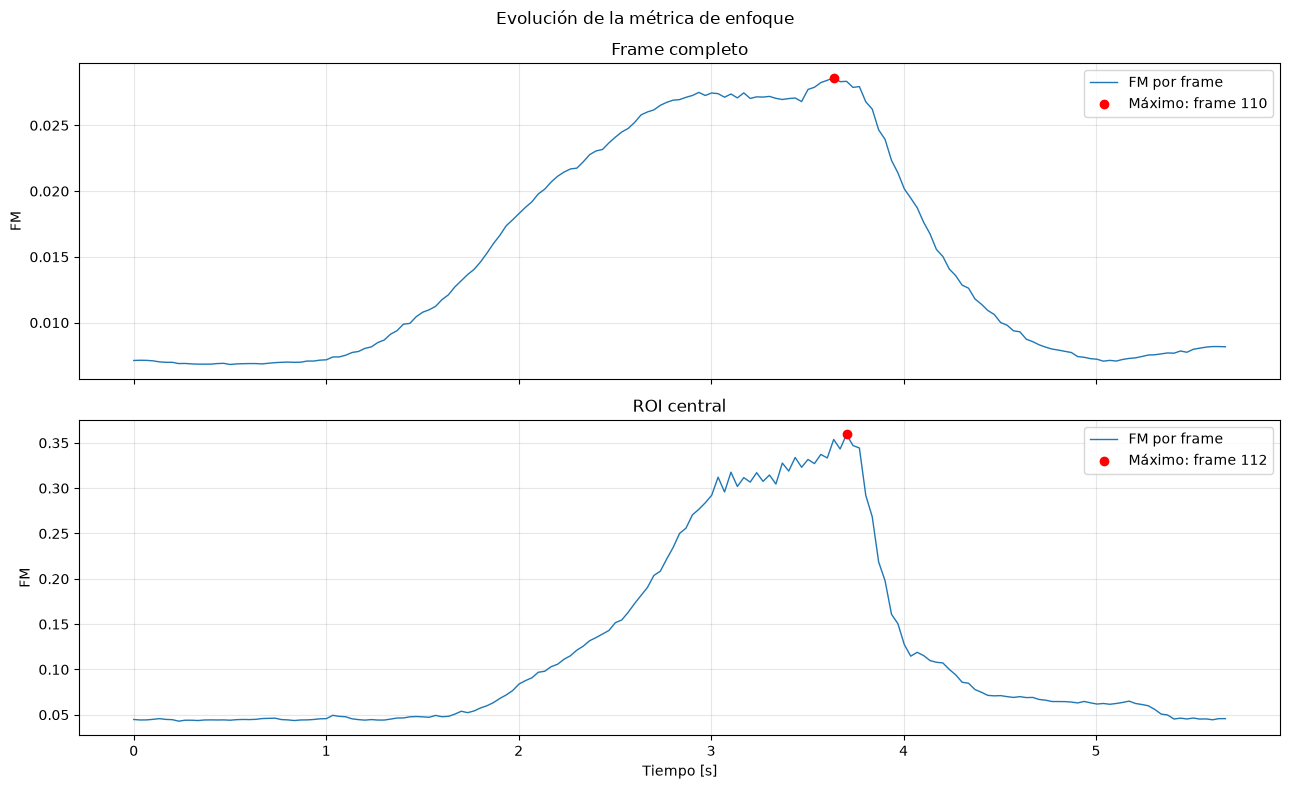

In [5]:
score_curves = {
    "Frame completo": full_frame_scores,
    "ROI central": roi_scores,
}
focus_maxima = {}

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, (label, scores) in zip(axes, score_curves.items()):
    peak_index = int(np.argmax(scores))
    maximum = {
        "frame": int(frame_indices[peak_index]) + 1,
        "time_seconds": float(frame_times[peak_index]),
        "FM": float(scores[peak_index]),
    }
    focus_maxima[label] = maximum

    ax.plot(frame_times, scores, linewidth=1, label="FM por frame")
    ax.scatter(
        maximum["time_seconds"],
        maximum["FM"],
        color="red",
        zorder=3,
        label=f"Máximo: frame {maximum['frame']}",
    )
    ax.set_title(label)
    ax.set_ylabel("FM")
    ax.grid(True, alpha=0.3)
    ax.legend()
    print(
        f"{label}: frame {maximum['frame']}, "
        f"t = {maximum['time_seconds']:.3f} s, FM = {maximum['FM']:.6f}"
    )

axes[-1].set_xlabel("Tiempo [s]")
fig.suptitle("Evolución de la métrica de enfoque")
fig.tight_layout()
plt.show()

## Análisis de resultados

Se procesaron 171 frames de un video de 640 × 360 píxeles a 29,97 FPS. La región central utilizada mide 202 × 114 píxeles y representa aproximadamente el 10% del área del frame, de acuerdo con la consigna.

En el experimento sobre el frame completo, la métrica FM alcanza su máximo en el frame 110, a los 3,637 s, con un valor de 0,028624. Para la ROI central, el máximo se detecta en el frame 112, a los 3,704 s, con un valor de 0,359389. La diferencia entre ambos máximos es de dos frames, aproximadamente 0,067 s; por lo tanto, las dos mediciones señalan una zona temporal de máximo enfoque muy similar.

En ambas curvas la métrica aumenta durante la primera parte del video, alcanza sus valores más altos aproximadamente entre los 3 y 3,8 s y luego desciende con rapidez. La curva del frame completo es más suave, mientras que la de la ROI presenta mayores fluctuaciones. Esto es compatible con que la medición global agregue información de distintas zonas de la escena, mientras que la ROI responde a los detalles locales del área central. A pesar de esa diferencia, ambas curvas coinciden en la ubicación temporal del máximo.

Los valores FM de ambas curvas no deben compararse directamente como si uno indicara cuánto más enfocada está una región que la otra: se calcularon sobre imágenes de distinto tamaño y contenido, con espectros de frecuencias diferentes. Para contrastar los experimentos resulta más informativo comparar el momento del máximo y la forma general de las curvas.

La detección automática selecciona el frame con el mayor FM observado en cada experimento. Este resultado identifica el máximo relativo dentro del video analizado; no constituye por sí solo una medida absoluta del enfoque óptico, ya que la métrica también puede verse afectada por la textura de la escena, el ruido y los cambios de iluminación.